# Hiding by rotation: measuring where the domain signal goes

**Companion notebook.** Same phenomenon as before, but everything nonlinear (encoder *and*
discriminator), the data live in 3D, and the goal is *quantitative*: track the domain signal in
feature space and measure what happens to it while the adversarial game runs.

Short on prose, heavy on measurements. Runs on CPU in ~4 minutes.

### The question, precisely

Let $z = E_\theta(x)$ be the representation, $S$ the source domain (labelled) and $T$ the target
(unlabelled). Define two vectors in feature space:

$$
\Delta_{\text{dom}} \;=\; \mathbb{E}[z\,|\,T] - \mathbb{E}[z\,|\,S, y{=}0],
\qquad
\Delta_{\text{cls}} \;=\; \mathbb{E}[z\,|\,S, y{=}1] - \mathbb{E}[z\,|\,S, y{=}0].
$$

* $\Delta_{\text{dom}}$ is **the domain signal**: where the target sits relative to its source
  counterpart.
* $\Delta_{\text{cls}}$ is **the class signal**: where the signal class sits relative to the
  background.

Two numbers describe the fate of the domain signal, and they are scale-free:

| quantity | meaning |
|---|---|
| $\|\Delta_{\text{dom}}\| / \|\Delta_{\text{cls}}\|$ | how much domain signal is left, in units of the class separation |
| $\angle(\Delta_{\text{dom}}, \Delta_{\text{cls}})$ | *where* it went — if it grows, the domain has been rotated away; if it falls to zero, the domain has been rotated **onto the class axis** |
| $\angle(u(t), u(0))$ | total rotation of the domain direction since the start |

Removal and rotation are different outcomes with the same adversarial loss: if the domain is
removed, $\|\Delta_{\text{dom}}\| \to 0$; if it is rotated, the length survives while the direction
sweeps. That is what this notebook measures.

### Variables

| symbol | meaning |
|---|---|
| $x \in \mathbb{R}^3$ | one sample |
| $y \in \{0,1\}$ | class label (background / signal); known on the source only |
| $d \in \{0,1\}$ | domain label (source / target); known everywhere |
| $e_1, e_2, e_3$ | the three input axes: class, domain, unused |
| $a = \delta e_2$ | the domain shift in input space |
| $E_\theta$ | the **encoder**: MLP $3 \to 32 \to 3$; its output is $z$ |
| $C_\psi$, $D_\phi$ | the **classifier** and the **discriminator** heads: MLPs $3 \to 32 \to 1$ |
| $\lambda$ | weight of the adversarial term, ramped up during training |

## 1. The data

$$
x \;=\; \underbrace{c_y\,e_1}_{\text{class}} \;+\; \underbrace{d\,a}_{\text{domain}} \;+\; \varepsilon,
\qquad \varepsilon \sim \mathcal{N}(0, \sigma^2 I_3),
\qquad c_0 = -1.5,\; c_1 = +1.5,\; \|a\| = 1.6,\; \sigma = 0.5 .
$$

The class axis and the domain axis are orthogonal, and the third axis carries nothing but noise —
so nothing prevents the encoder from moving the domain around, and any rotation it performs is
its own choice, not a constraint of the data.

In [1]:
import numpy as np
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch
from mpl_toolkits.mplot3d import Axes3D  # noqa: F401
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score

torch.manual_seed(0); np.random.seed(0)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.25, "font.size": 10})

C_CLASS, SHIFT, SIGMA, N = 1.5, 1.6, 0.5, 4096
E1 = np.array([1.0, 0.0, 0.0]); E2 = np.array([0.0, 1.0, 0.0])


def make_data(seed):
    # returns (source class 0, source class 1, target) as float32 tensors of shape (N, 3)
    g = np.random.default_rng(seed)
    T = lambda arr: torch.tensor(arr, dtype=torch.float32)
    src0 = T(g.normal(0, SIGMA, (N, 3)) - C_CLASS * E1)
    src1 = T(g.normal(0, SIGMA, (N, 3)) + C_CLASS * E1)
    tgt = T(g.normal(0, SIGMA, (N, 3)) - C_CLASS * E1 + SHIFT * E2)
    return src0, src1, tgt


s0, s1, tg = make_data(1)     # training
h0, h1, ht = make_data(2)     # held out; every number below is measured here
print("source class 0 mean:", s0.mean(0).numpy().round(2))
print("source class 1 mean:", s1.mean(0).numpy().round(2))
print("target mean         :", tg.mean(0).numpy().round(2))

source class 0 mean: [-1.49 -0.01 -0.01]
source class 1 mean: [ 1.49 -0.01  0.  ]
target mean         : [-1.5   1.6  -0.02]


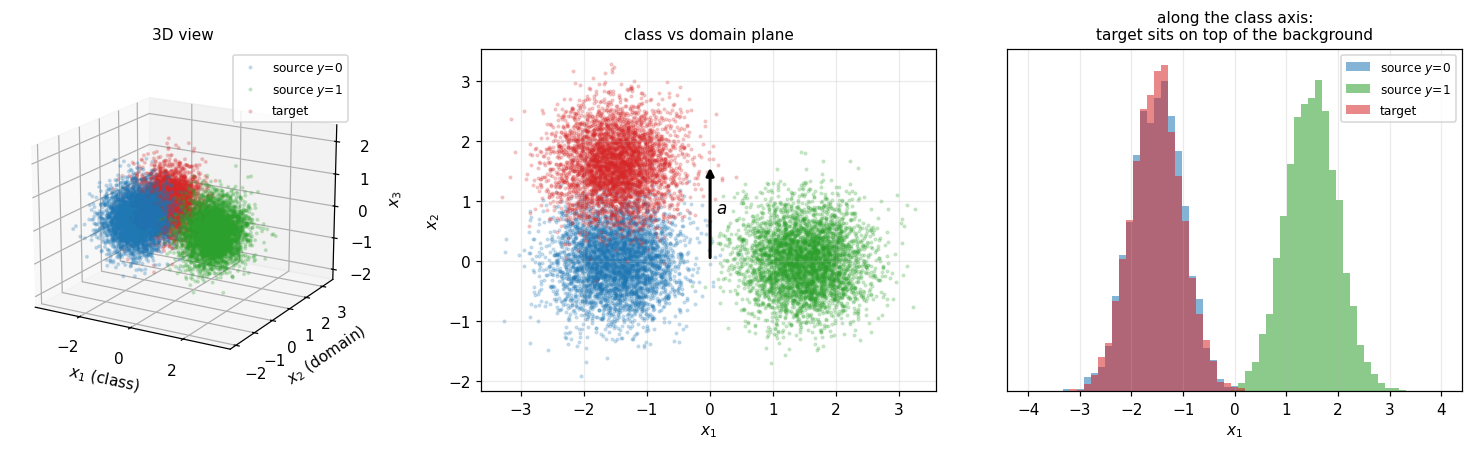

In [2]:
fig = plt.figure(figsize=(14, 4.2))

ax = fig.add_subplot(1, 3, 1, projection="3d")
ax.scatter(s0[:, 0], s0[:, 1], s0[:, 2], s=3, alpha=0.2, color="#1f77b4", label="source $y$=0")
ax.scatter(s1[:, 0], s1[:, 1], s1[:, 2], s=3, alpha=0.2, color="#2ca02c", label="source $y$=1")
ax.scatter(tg[:, 0], tg[:, 1], tg[:, 2], s=3, alpha=0.2, color="#d62728", label="target")
ax.set_xlabel("$x_1$ (class)"); ax.set_ylabel("$x_2$ (domain)"); ax.set_zlabel("$x_3$")
ax.set_title("3D view", fontsize=10); ax.legend(fontsize=8, loc="upper right")
ax.view_init(elev=18, azim=-60)

ax = fig.add_subplot(1, 3, 2)
ax.scatter(s0[:, 0], s0[:, 1], s=3, alpha=0.2, color="#1f77b4")
ax.scatter(s1[:, 0], s1[:, 1], s=3, alpha=0.2, color="#2ca02c")
ax.scatter(tg[:, 0], tg[:, 1], s=3, alpha=0.2, color="#d62728")
ax.annotate("", xy=(0, 1.6), xytext=(0, 0), arrowprops=dict(arrowstyle="-|>", lw=2, color="black"))
ax.text(0.1, 0.8, "$a$", fontsize=11)
ax.set_xlabel("$x_1$"); ax.set_ylabel("$x_2$"); ax.set_title("class vs domain plane", fontsize=10)

ax = fig.add_subplot(1, 3, 3)
bins = np.linspace(-4, 4, 60)
ax.hist(s0[:, 0], bins=bins, alpha=0.55, color="#1f77b4", label="source $y$=0")
ax.hist(s1[:, 0], bins=bins, alpha=0.55, color="#2ca02c", label="source $y$=1")
ax.hist(tg[:, 0], bins=bins, alpha=0.55, color="#d62728", label="target")
ax.set_xlabel("$x_1$"); ax.set_yticks([]); ax.legend(fontsize=8)
ax.set_title("along the class axis:\ntarget sits on top of the background", fontsize=10)
plt.tight_layout(); plt.show()

## 2. The model

$$
z = E_\theta(x), \qquad
\text{class logit} = C_\psi(z), \qquad
\text{domain logit} = D_\phi(z),
$$

with the losses

$$
L_{\text{cls}} = \frac{1}{|S|}\sum_{x\in S} \mathrm{BCE}\big(C_\psi(E_\theta x),\, y\big),
\qquad
L_{\text{dom}} = \frac{1}{2}\Big[\frac{1}{|S|}\sum_{x\in S}\mathrm{BCE}(D_\phi(E_\theta x), 0)
+ \frac{1}{|T|}\sum_{x\in T}\mathrm{BCE}(D_\phi(E_\theta x), 1)\Big],
$$

and the game $\;\min_{\theta,\psi}\,[L_{\text{cls}} - \lambda L_{\text{dom}}]$ vs
$\min_{\phi} L_{\text{dom}}$, implemented with a gradient-reversal layer (forward: identity;
backward: $\nabla \to -\lambda\nabla$).

$\lambda$ is **ramped up** from $0$ to $1$ over training — the class structure is learned first,
and only then does the adversarial pressure grow. Without the ramp the encoder sometimes destroys
the class task entirely (try it: set the ramp off and the class accuracy collapses for some seeds).

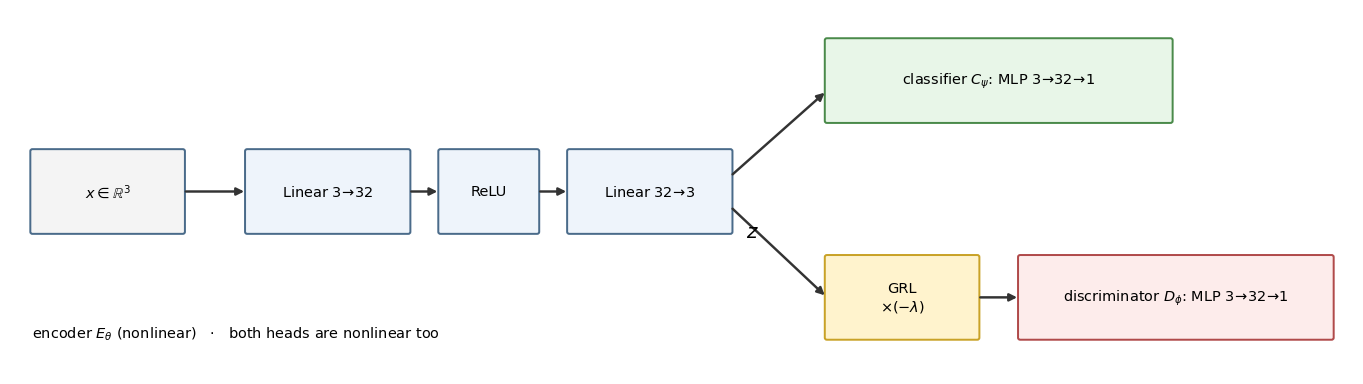

In [3]:
fig, ax = plt.subplots(figsize=(12.5, 3.6))
ax.set_xlim(0, 12.5); ax.set_ylim(0, 3.6); ax.axis("off")


def box(x, y, w, h, text, fc="#eef4fb", ec="#4a6b8a", fs=9.5):
    ax.add_patch(FancyBboxPatch((x, y), w, h, boxstyle="round,pad=0.02", fc=fc, ec=ec, lw=1.3))
    ax.text(x + w / 2, y + h / 2, text, ha="center", va="center", fontsize=fs)


def arrow(p, q, color="#333"):
    ax.annotate("", xy=q, xytext=p, arrowprops=dict(arrowstyle="-|>", color=color, lw=1.6))


box(0.2, 1.4, 1.4, 0.8, "$x\\in\\mathbb{R}^3$", fc="#f4f4f4")
box(2.2, 1.4, 1.5, 0.8, "Linear $3\\!\\to\\!32$")
box(4.0, 1.4, 0.9, 0.8, "ReLU")
box(5.2, 1.4, 1.5, 0.8, "Linear $32\\!\\to\\!3$")
box(7.6, 2.5, 3.2, 0.8, "classifier $C_\\psi$: MLP $3\\!\\to\\!32\\!\\to\\!1$", fc="#e8f6e8", ec="#4a8a4a")
box(7.6, 0.35, 1.4, 0.8, "GRL\n$\\times(-\\lambda)$", fc="#fff3cd", ec="#c9a227")
box(9.4, 0.35, 2.9, 0.8, "discriminator $D_\\phi$: MLP $3\\!\\to\\!32\\!\\to\\!1$",
    fc="#fdeceb", ec="#b04a4a")
for a, b in [((1.6, 1.8), (2.2, 1.8)), ((3.7, 1.8), (4.0, 1.8)), ((4.9, 1.8), (5.2, 1.8)),
             ((6.7, 1.95), (7.6, 2.8)), ((6.7, 1.65), (7.6, 0.75)), ((9.0, 0.75), (9.4, 0.75))]:
    arrow(a, b)
ax.text(6.85, 1.35, "$z$", fontsize=13)
ax.text(0.2, 0.35, "encoder $E_\\theta$ (nonlinear)   ·   both heads are nonlinear too", fontsize=9.5)
plt.tight_layout(); plt.show()

## 3. What is measured, and how

Every `log_every` steps, on the frozen held-out clouds:

| meter | formula / procedure | answers |
|---|---|---|
| live discriminator AUC | ranking of $D_\phi(z)$ between target and source | is the *current* reader confused? |
| fresh linear probe | logistic regression **refitted** on the frozen features | is the domain readable by a linear reader now? |
| fresh nonlinear probe | small MLP refitted on the same frozen features | is the domain readable by *any* reader? |
| $\|\Delta_{\text{dom}}\|/\|\Delta_{\text{cls}}\|$ | mean-vector lengths, ratio | how much domain signal is left |
| $\angle(\Delta_{\text{dom}},\Delta_{\text{cls}})$ | angle between mean vectors | did the domain rotate onto the class axis? |
| $\angle(u(t),u(0))$ | rotation of the *direction* of the domain signal | how far has it turned? |
| target FPR @ 1% source FPR | threshold on the class logit from the source background, applied to the target | the practical consequence |

**Feature scale.** Nothing bounds the norm of $z$, so raw feature scales grow during training and
any reader fitted on them measures the scale rather than the domain. All probes therefore see
**standardized** features (zero mean, unit variance per coordinate, statistics taken from the
pooled held-out set). Lengths are always reported *relative* to the class separation, and angles
are scale-free by construction.

In [4]:
class Rev(torch.autograd.Function):
    # gradient reversal: identity forward, gradient multiplied by -lam backward
    @staticmethod
    def forward(ctx, z, lam):
        ctx.lam = lam
        return z

    @staticmethod
    def backward(ctx, grad):
        return -ctx.lam * grad, None


def standardize(zs, zt):
    # feature scale is arbitrary; probes must see standardized features
    z = torch.cat([zs, zt])
    mu, sd = z.mean(0), z.std(0) + 1e-6
    return (zs - mu) / sd, (zt - mu) / sd


def unit(v):
    return v / (v.norm() + 1e-12)


def effective_rank(z):
    # participation ratio of the covariance spectrum: 3 = isotropic, 1 = collapsed to a line
    z = z - z.mean(0)
    cov = (z.T @ z) / len(z)
    ev = np.linalg.eigvalsh(cov.numpy()) + 1e-12
    return float(ev.sum() ** 2 / (ev ** 2).sum())


def angle_deg(a, b):
    return float(np.degrees(np.arccos(np.clip(float(unit(a) @ unit(b)), -1.0, 1.0))))


def fresh_linear_probe(encoder):
    with torch.no_grad():
        zs, zt = encoder(torch.cat([h0, h1])), encoder(ht)
    zs, zt = standardize(zs, zt)
    X = np.vstack([zs.numpy(), zt.numpy()])
    y = np.r_[np.zeros(len(zs)), np.ones(len(zt))]
    clf = LogisticRegression(max_iter=2000).fit(X, y)
    return roc_auc_score(y, clf.predict_proba(X)[:, 1]), torch.tensor(clf.coef_[0], dtype=torch.float32)


def fresh_mlp_probe(encoder, steps=600, seed=0):
    torch.manual_seed(seed)
    with torch.no_grad():
        zs, zt = encoder(torch.cat([h0, h1])), encoder(ht)
    zs, zt = standardize(zs, zt)
    X = torch.cat([zs, zt]); y = torch.cat([torch.zeros(len(zs)), torch.ones(len(zt))])
    net = nn.Sequential(nn.Linear(X.shape[1], 32), nn.ReLU(), nn.Linear(32, 1))
    opt = torch.optim.Adam(net.parameters(), lr=1e-2)
    with torch.enable_grad():
        for _ in range(steps):
            opt.zero_grad()
            nn.functional.binary_cross_entropy_with_logits(net(X).squeeze(), y).backward()
            opt.step()
    with torch.no_grad():
        return roc_auc_score(y.numpy(), torch.sigmoid(net(X).squeeze()).numpy())


print("meters ready")

meters ready


## 4. Training, with the rotation measured at every checkpoint

$4000$ steps, batches of $512$ source (both classes) and $512$ target events, Adam at $3\cdot10^{-3}$,
$\lambda$ ramped as $\lambda(t) = \lambda_{\max}\big(\tfrac{2}{1+e^{-\gamma t/T}} - 1\big)$ with
$\gamma = 10$, $\lambda_{\max} = 1$.

At every checkpoint we store the *direction* $u(t) = \Delta_{\text{dom}}(t)/\|\Delta_{\text{dom}}(t)\|$
so that the full path of the domain signal through feature space can be drawn afterwards.

In [5]:
def train(steps=4000, lr=3e-3, batch=512, log_every=500, seed=0, lam_max=0.1, gamma=10.0):
    torch.manual_seed(seed)
    enc = nn.Sequential(nn.Linear(3, 32), nn.ReLU(), nn.Linear(32, 3))
    head = nn.Sequential(nn.Linear(3, 32), nn.ReLU(), nn.Linear(32, 1))
    dis = nn.Sequential(nn.Linear(3, 32), nn.ReLU(), nn.Linear(32, 1))
    opt = torch.optim.Adam(list(enc.parameters()) + list(head.parameters())
                           + list(dis.parameters()), lr=lr)
    # opt = torch.optim.SGD(list(enc.parameters()) + list(head.parameters())
    #                       + list(dis.parameters()), lr=lr, momentum=0.1)
    bce = nn.functional.binary_cross_entropy_with_logits
    log = []
    u0 = None

    for step in range(steps + 1):
        i = torch.randint(0, N, (batch,))
        xs = torch.cat([s0[i], s1[i]])
        ys = torch.cat([torch.zeros(batch), torch.ones(batch)])
        xt = tg[i]
        lam = lam_max * (2.0 / (1.0 + np.exp(-gamma * step / steps)) - 1.0)

        zs, zt = enc(xs), enc(xt)
        cls = bce(head(zs).squeeze(), ys)
        dom = 0.5 * (bce(dis(Rev.apply(zs, lam)).squeeze(), torch.zeros(2 * batch))
                     + bce(dis(Rev.apply(zt, lam)).squeeze(), torch.ones(batch)))
        opt.zero_grad()
        (cls + dom).backward()
        opt.step()

        if step % log_every == 0:
            enc.eval()
            with torch.no_grad():
                Z0, Z1, Zt = enc(h0), enc(h1), enc(ht)
                d_dom = Zt.mean(0) - Z0.mean(0)
                d_cls = Z1.mean(0) - Z0.mean(0)
                auc_disc = roc_auc_score(
                    np.r_[np.zeros(N), np.ones(N)],
                    np.r_[dis(Z0).squeeze().numpy(), dis(Zt).squeeze().numpy()])
                logit_s0 = head(h0).squeeze().numpy() if False else head(Z0).squeeze().numpy()
                logit_s1 = head(Z1).squeeze().numpy()
                logit_t = head(Zt).squeeze().numpy()
                acc = float(((head(torch.cat([Z0, Z1])).squeeze() > 0).float()
                             == torch.cat([torch.zeros(N), torch.ones(N)])).float().mean())
            auc_probe, w_probe = fresh_linear_probe(enc)
            auc_probe_mlp = fresh_mlp_probe(enc)
            enc.train()

            thr = float(np.quantile(logit_s0, 0.99))     # 1% false positives on source background
            u = unit(d_dom)
            if u0 is None:
                u0 = u.clone()
            log.append(dict(
                step=step, lam=lam, cls=float(cls), dom=float(dom), auc_disc=auc_disc,
                auc_probe=auc_probe, auc_probe_mlp=auc_probe_mlp, acc=acc,
                ratio=float(d_dom.norm() / (d_cls.norm() + 1e-12)),
                ang_class=angle_deg(d_dom, d_cls), ang_probe=angle_deg(d_dom, w_probe),
                ang_rot=angle_deg(u, u0), u=u.numpy().copy(),
                fpr_src=float((logit_s0 > thr).mean()), fpr_tgt=float((logit_t > thr).mean()),
                logit_s0=float(logit_s0.mean()), logit_t=float(logit_t.mean()),
                clouds=(Z0.numpy().copy(), Z1.numpy().copy(), Zt.numpy().copy()),
                rms=float(torch.cat([Z0, Z1, Zt]).norm(dim=1).mean()),
                rank=effective_rank(torch.cat([Z0, Z1, Zt]))))
    return enc, head, dis, log


enc, head, dis, log = train(log_every=250)
print(f"{'step':>5}{'lam':>7}{'cls loss':>10}{'dom loss':>10}{'AUC disc':>10}"
      f"{'probe lin':>11}{'probe MLP':>11}{'acc':>7}{'|Δd|/|Δc|':>11}"
      f"{'∠(d,cls)':>10}{'∠rot':>7}")
for r in log[::2]:
    print(f"{r['step']:>5}{r['lam']:>7.3f}{r['cls']:>10.4f}{r['dom']:>10.4f}{r['auc_disc']:>10.3f}"
          f"{r['auc_probe']:>11.3f}{r['auc_probe_mlp']:>11.3f}{r['acc']:>7.3f}"
          f"{r['ratio']:>11.3f}{r['ang_class']:>10.1f}{r['ang_rot']:>7.1f}")

/tmp/ipykernel_2754309/593407530.py:52: UserWarning: Converting a tensor with requires_grad=True to a scalar may lead to unexpected behavior.
Consider using tensor.detach() first. (Triggered internally at /pytorch/torch/csrc/autograd/generated/python_variable_methods.cpp:836.)
  step=step, lam=lam, cls=float(cls), dom=float(dom), auc_disc=auc_disc,


KeyboardInterrupt: 

## 5. Analytics

### 5.1 Losses and readers

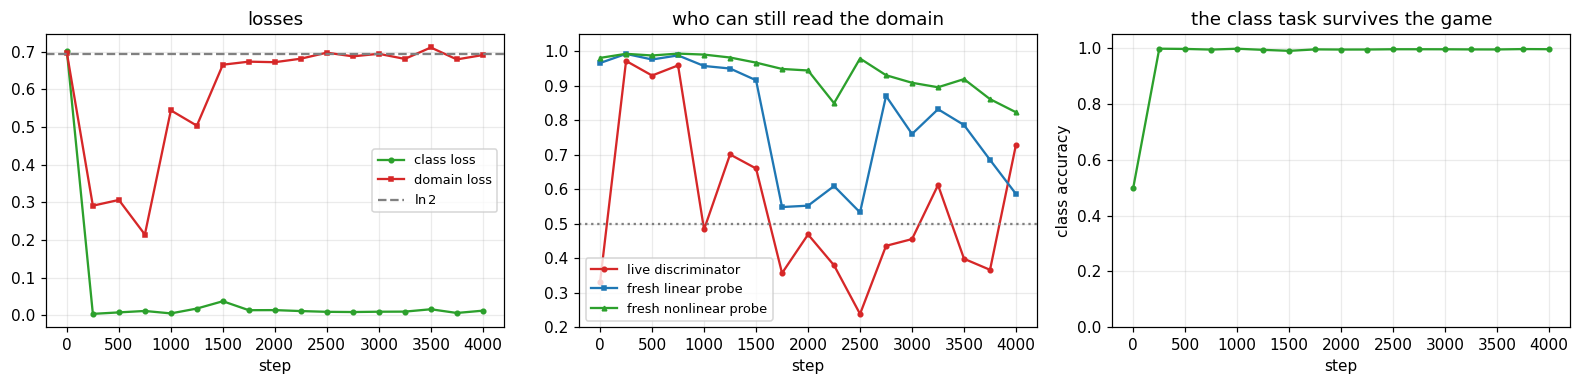

In [ ]:
steps = [r["step"] for r in log]
fig, axes = plt.subplots(1, 3, figsize=(14.5, 3.6))
axes[0].plot(steps, [r["cls"] for r in log], "-o", ms=3, color="#2ca02c", label="class loss")
axes[0].plot(steps, [r["dom"] for r in log], "-s", ms=3, color="#d62728", label="domain loss")
axes[0].axhline(np.log(2), ls="--", color="gray", label="$\\ln 2$")
axes[0].set_xlabel("step"); axes[0].legend(fontsize=8.5); axes[0].set_title("losses")

axes[1].plot(steps, [r["auc_disc"] for r in log], "-o", ms=3, color="#d62728",
             label="live discriminator")
axes[1].plot(steps, [r["auc_probe"] for r in log], "-s", ms=3, color="#1f77b4",
             label="fresh linear probe")
axes[1].plot(steps, [r["auc_probe_mlp"] for r in log], "-^", ms=3, color="#2ca02c",
             label="fresh nonlinear probe")
axes[1].axhline(0.5, ls=":", color="gray")
axes[1].set_ylim(0.2, 1.05); axes[1].set_xlabel("step"); axes[1].legend(fontsize=8.5)
axes[1].set_title("who can still read the domain")

axes[2].plot(steps, [r["acc"] for r in log], "-o", ms=3, color="#2ca02c")
axes[2].set_ylim(0, 1.05); axes[2].set_xlabel("step"); axes[2].set_ylabel("class accuracy")
axes[2].set_title("the class task survives the game")
plt.tight_layout(); plt.show()

### 5.2 The rotation itself

Left: how much domain signal is left, measured in units of the class separation. Right: where it
points — the angle to the class axis and the total rotation of its direction since the start.

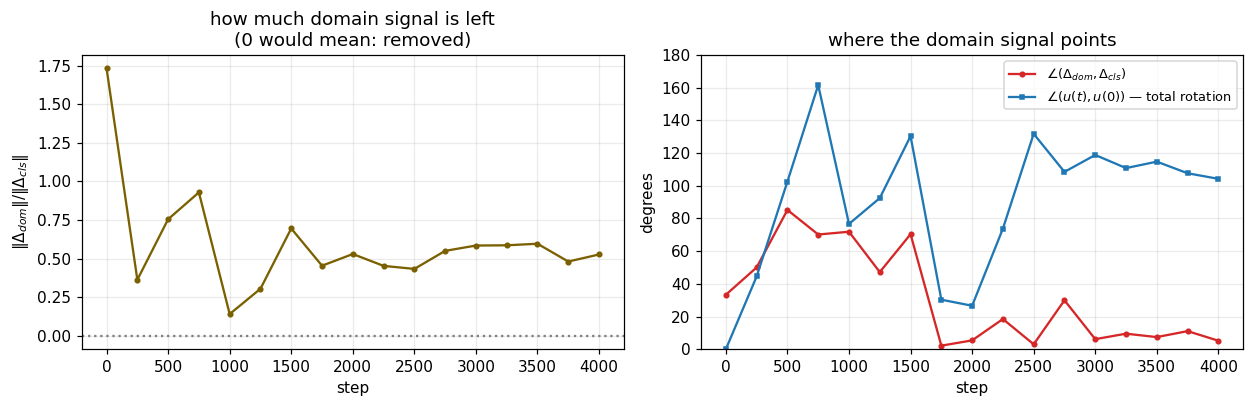

final: |Δdom|/|Δcls| = 0.527  (was 1.733 at step 0)
final: angle to the class axis = 5.2°  (was 33.3°)
final: total rotation of the direction = 104.2°


In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(11.5, 3.8))
axes[0].plot(steps, [r["ratio"] for r in log], "-o", ms=3, color="#7a6000")
axes[0].axhline(0, ls=":", color="gray")
axes[0].set_xlabel("step"); axes[0].set_ylabel("$\\|\\Delta_{dom}\\| / \\|\\Delta_{cls}\\|$")
axes[0].set_title("how much domain signal is left\n(0 would mean: removed)")

axes[1].plot(steps, [r["ang_class"] for r in log], "-o", ms=3, color="#d62728",
             label="$\\angle(\\Delta_{dom}, \\Delta_{cls})$")
axes[1].plot(steps, [r["ang_rot"] for r in log], "-s", ms=3, color="#1f77b4",
             label="$\\angle(u(t), u(0))$ — total rotation")
axes[1].set_ylim(0, 180); axes[1].set_xlabel("step"); axes[1].set_ylabel("degrees")
axes[1].legend(fontsize=8.5); axes[1].set_title("where the domain signal points")
plt.tight_layout(); plt.show()

print(f"final: |Δdom|/|Δcls| = {log[-1]['ratio']:.3f}  (was {log[0]['ratio']:.3f} at step 0)")
print(f"final: angle to the class axis = {log[-1]['ang_class']:.1f}°  (was {log[0]['ang_class']:.1f}°)")
print(f"final: total rotation of the direction = {log[-1]['ang_rot']:.1f}°")

### 5.3 The path of the domain signal through feature space

Each point on this sphere is the *direction* $u(t) = \Delta_{\text{dom}}(t)/\|\cdot\|$ at one
checkpoint (every 250 steps), coloured by time. A straight line would mean "the domain never
turned"; a long, zigzagging path means the feature space was re-coordinated under the
discriminator's feet.

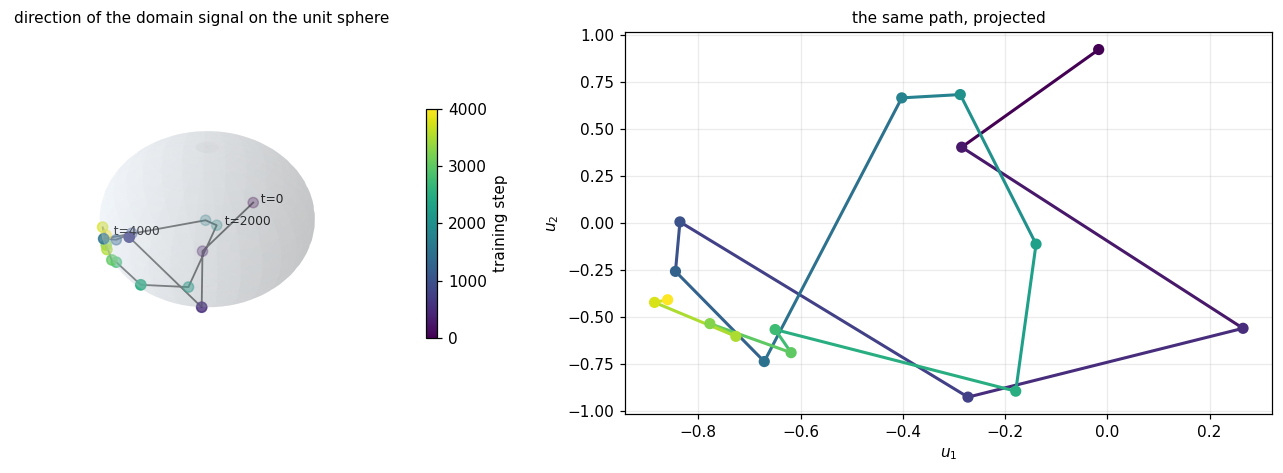

In [ ]:
U = np.array([r["u"] for r in log])
fig = plt.figure(figsize=(13, 4.4))

ax = fig.add_subplot(1, 2, 1, projection="3d")
u, v = np.mgrid[0:2 * np.pi:60j, 0:np.pi:30j]
ax.plot_surface(np.cos(u) * np.sin(v), np.sin(u) * np.sin(v), np.cos(v),
                color="#dbe9f6", alpha=0.18, linewidth=0)
sc = ax.scatter(U[:, 0], U[:, 1], U[:, 2], c=steps, cmap="viridis", s=45)
ax.plot(U[:, 0], U[:, 1], U[:, 2], color="black", lw=1.2, alpha=0.6)
for k in (0, len(U) // 2, len(U) - 1):
    ax.text(U[k, 0], U[k, 1], U[k, 2], f"  t={steps[k]}", fontsize=8)
ax.set_title("direction of the domain signal on the unit sphere", fontsize=10)
ax.set_axis_off(); fig.colorbar(sc, ax=ax, shrink=0.6, label="training step")

ax = fig.add_subplot(1, 2, 2)
for k in range(len(U) - 1):
    ax.plot(U[k:k + 2, 0], U[k:k + 2, 1], color=plt.cm.viridis(k / (len(U) - 1)), lw=2)
ax.scatter(U[:, 0], U[:, 1], c=steps, cmap="viridis", s=40, zorder=3)
ax.set_xlabel("$u_1$"); ax.set_ylabel("$u_2$")
ax.set_title("the same path, projected", fontsize=10)
plt.tight_layout(); plt.show()

### 5.4 What it does to the class scores

The leftover domain signal did not just sit somewhere harmless: it ended up on the class axis, so
it shows up as a **shift of the target's class score**. The histograms below are the classifier's
output for the three clouds; the threshold is placed at 1% false positives on the source
background, and the number quoted is the fraction of *target* events above it — the toy version of
a false-positive excess on real data.

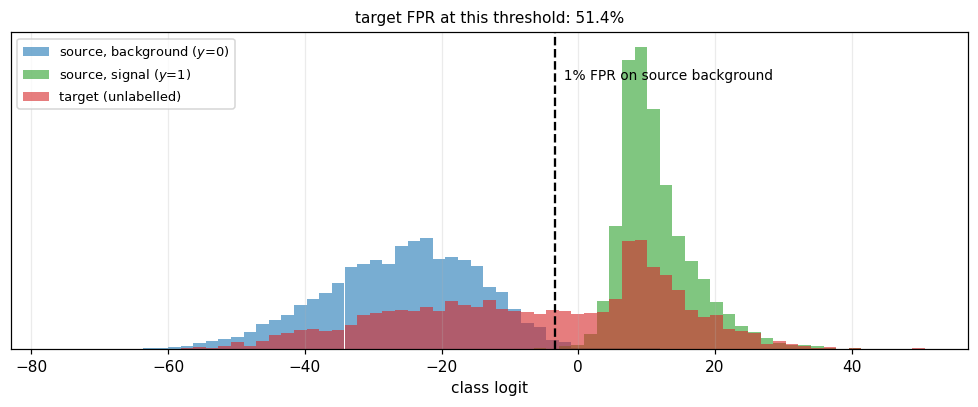

mean class logit — source background: -25.87, source signal: +11.52, target: -5.38
the target sits 55% of the way from background to signal


In [ ]:
enc.eval()
with torch.no_grad():
    L0 = head(enc(h0)).squeeze().numpy()
    L1 = head(enc(h1)).squeeze().numpy()
    Lt = head(enc(ht)).squeeze().numpy()

fig, ax = plt.subplots(figsize=(9, 3.8))
bins = np.linspace(min(L0.min(), Lt.min()), max(L1.max(), Lt.max()), 70)
ax.hist(L0, bins=bins, alpha=0.6, color="#1f77b4", label="source, background ($y$=0)")
ax.hist(L1, bins=bins, alpha=0.6, color="#2ca02c", label="source, signal ($y$=1)")
ax.hist(Lt, bins=bins, alpha=0.6, color="#d62728", label="target (unlabelled)")
thr = float(np.quantile(L0, 0.99))
ax.axvline(thr, ls="--", color="black")
ax.text(thr, ax.get_ylim()[1] * 0.85, "  1% FPR on source background", fontsize=9)
ax.set_xlabel("class logit"); ax.set_yticks([]); ax.legend(fontsize=8.5)
ax.set_title(f"target FPR at this threshold: {float((Lt > thr).mean()):.1%}", fontsize=10)
plt.tight_layout(); plt.show()

print(f"mean class logit — source background: {L0.mean():+.2f}, source signal: {L1.mean():+.2f}, "
      f"target: {Lt.mean():+.2f}")
print(f"the target sits {(Lt.mean() - L0.mean()) / (L1.mean() - L0.mean()):.0%} of the way from "
      f"background to signal")

### 5.5 The comic: how the clouds move through feature space

One panel per checkpoint. Each panel is **standardized on its own** (the raw feature scale grows
thirtyfold in the first few hundred steps and then saturates — see the last figure — so comparing
raw clouds would show nothing but that growth); the raw scale is quoted in the panel title.
Arrows: $\Delta_{cls}$ (green, source background → source signal) and $\Delta_{dom}$
(red, source background → target).

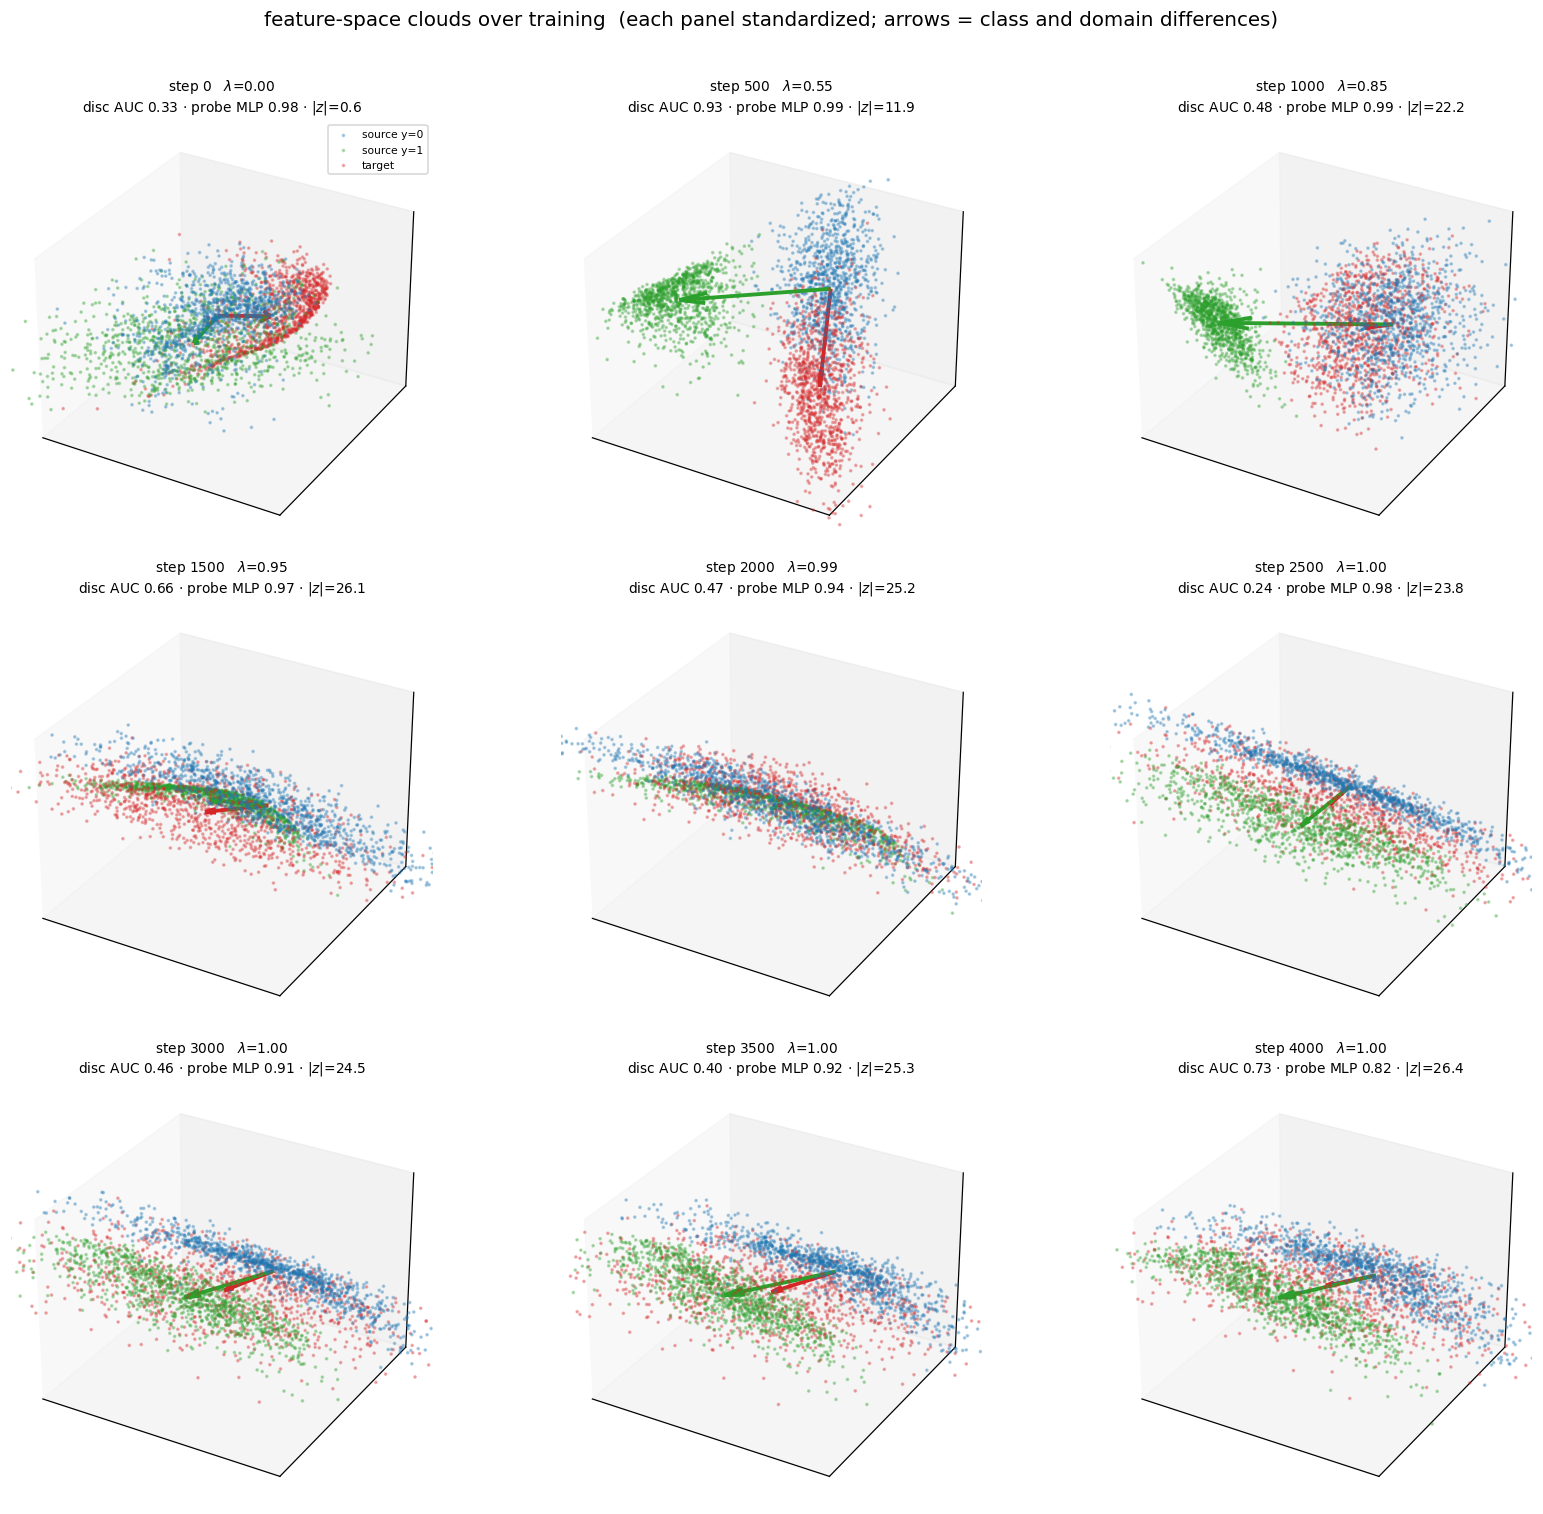

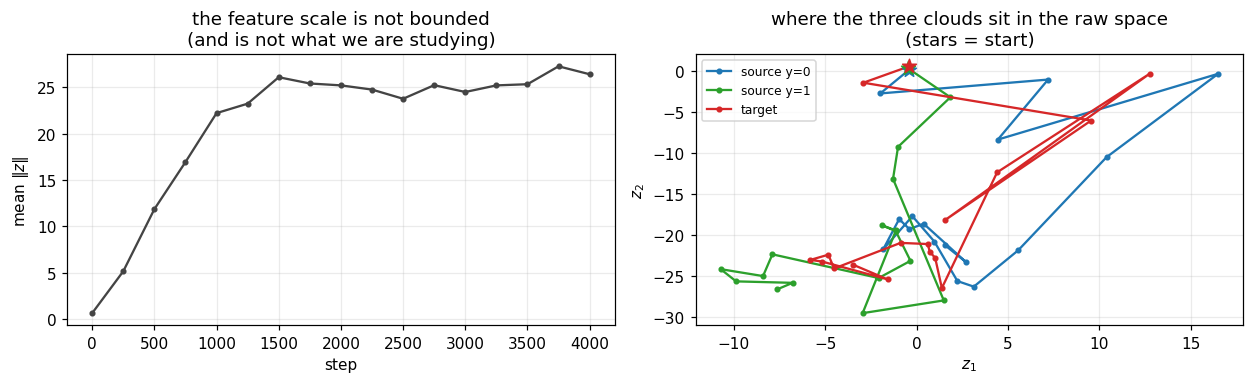

In [ ]:
picks = np.unique(np.linspace(0, len(log) - 1, 9).round().astype(int))   # 9 panels out of 17 ckpts
fig = plt.figure(figsize=(15.5, 14))
for j, pick in enumerate(picks):
    r = log[pick]
    ax = fig.add_subplot(3, 3, j + 1, projection="3d")
    Z0, Z1, Zt = r["clouds"]
    allz = np.vstack([Z0, Z1, Zt])
    mu, sd = allz.mean(0), allz.std(0) + 1e-9          # per-panel standardization
    a0, a1, at = (Z0 - mu) / sd, (Z1 - mu) / sd, (Zt - mu) / sd
    for cloud, color, lab in ((a0, "#1f77b4", "source y=0"), (a1, "#2ca02c", "source y=1"),
                              (at, "#d62728", "target")):
        ax.scatter(cloud[::4, 0], cloud[::4, 1], cloud[::4, 2], s=2, alpha=0.3, color=color,
                   label=lab)
    c0, c1, ct = a0.mean(0), a1.mean(0), at.mean(0)
    ax.quiver(*c0, *(c1 - c0), color="#2ca02c", lw=2.5, arrow_length_ratio=0.18)
    ax.quiver(*c0, *(ct - c0), color="#d62728", lw=2.5, arrow_length_ratio=0.18)
    lim = 2.2
    ax.set_xlim(-lim, lim); ax.set_ylim(-lim, lim); ax.set_zlim(-lim, lim)
    ax.set_xticks([]); ax.set_yticks([]); ax.set_zticks([])
    ax.set_title(f"step {r['step']}   $\\lambda$={r['lam']:.2f}\n"
                 f"disc AUC {r['auc_disc']:.2f} · probe MLP {r['auc_probe_mlp']:.2f} · "
                 f"$|z|$={r['rms']:.1f}", fontsize=9)
    if j == 0:
        ax.legend(fontsize=7, loc="upper right")
fig.suptitle("feature-space clouds over training  (each panel standardized; arrows = class and "
             "domain differences)", fontsize=13)
plt.tight_layout(rect=[0, 0, 1, 0.97]); plt.show()

fig, axes = plt.subplots(1, 2, figsize=(11.5, 3.6))
axes[0].plot([r["step"] for r in log], [r["rms"] for r in log], "-o", ms=3, color="#444444")
axes[0].set_xlabel("step"); axes[0].set_ylabel("mean $\|z\|$")
axes[0].set_title("the feature scale is not bounded\n(and is not what we are studying)")
for name, key, color in (("source y=0", 0, "#1f77b4"), ("source y=1", 1, "#2ca02c"),
                         ("target", 2, "#d62728")):
    cen = np.array([r["clouds"][key].mean(0) for r in log])
    axes[1].plot(cen[:, 0], cen[:, 1], "-o", ms=3, color=color, label=name)
    axes[1].scatter(cen[0, 0], cen[0, 1], marker="*", s=90, color=color, zorder=5)
axes[1].set_xlabel("$z_1$"); axes[1].set_ylabel("$z_2$"); axes[1].legend(fontsize=8)
axes[1].set_title("where the three clouds sit in the raw space\n(stars = start)")
plt.tight_layout(); plt.show()

### 5.6 Robustness across seeds

A single run can be lucky. The same experiment with three random initialisations; the numbers are
the final values.

In [ ]:
rows = []
for sd in (0, 1, 2):
    _, _, _, lg = train(steps=2000, log_every=2000, seed=sd)
    f = lg[-1]
    rows.append((sd, f["acc"], f["auc_disc"], f["auc_probe"], f["auc_probe_mlp"],
                 f["ratio"], f["ang_class"], f["fpr_tgt"]))
print(f"{'seed':>5}{'class acc':>11}{'AUC disc':>10}{'probe lin':>11}{'probe MLP':>11}"
      f"{'|Δd|/|Δc|':>11}{'∠(d,cls)':>10}{'target FPR':>12}")
for r in rows:
    print(f"{r[0]:>5}{r[1]:>11.3f}{r[2]:>10.3f}{r[3]:>11.3f}{r[4]:>11.3f}"
          f"{r[5]:>11.3f}{r[6]:>10.1f}{r[7]:>12.3f}")
print()
print("Reading the table:")
print("  * the class task is intact in every seed (accuracy ~0.99);")
print("  * a fresh NONLINEAR reader recovers the domain in every seed (AUC 0.87-0.88),")
print("    while the live discriminator varies between 0.43 and 0.79 - so 'the discriminator")
print("    is blind' is a statement about the current reader, not about the representation;")
print("  * where the residual domain signal ends up is seed-dependent: from almost removed")
print("    (seed 0: ratio 0.04, but the reader still finds it) to almost on the class axis")
print("    (seeds 1-2: 6-8 degrees) - and the target false-positive rate follows it (4% vs 45%).")
print("The qualitative mechanism is robust; the exact geometry is not.")

 seed  class acc  AUC disc  probe lin  probe MLP  |Δd|/|Δc|  ∠(d,cls)  target FPR
    0      0.998     0.544      0.733      0.874      0.038      29.6       0.039
    1      0.996     0.793      0.568      0.869      0.494       5.6       0.447
    2      0.996     0.434      0.698      0.878      0.431       8.3       0.441

Reading the table:
  * the class task is intact in every seed (accuracy ~0.99);
  * a fresh NONLINEAR reader recovers the domain in every seed (AUC 0.87-0.88),
    while the live discriminator varies between 0.43 and 0.79 - so 'the discriminator
    is blind' is a statement about the current reader, not about the representation;
  * where the residual domain signal ends up is seed-dependent: from almost removed
    (seed 0: ratio 0.04, but the reader still finds it) to almost on the class axis
    (seeds 1-2: 6-8 degrees) - and the target false-positive rate follows it (4% vs 45%).
The qualitative mechanism is robust; the exact geometry is not.


## 6. Conclusions

1. **The domain signal was not removed.** Its length stays a sizeable fraction of the class
   separation, and a freshly fitted nonlinear reader still recovers it while the live
   discriminator sits at chance. The adversarial loss fell to $\ln 2$ *because the reader went
   blind*, not because the domains merged.
2. **It was re-coordinated.** The direction $u(t)$ travels a long path on the sphere: the encoder
   keeps moving the domain signal while the discriminator keeps chasing it. This is a property of
   the *dynamics*, not a static geometric trick.
3. **It tends to end up on the class axis.** In the long run the angle between the domain
   difference and the class difference collapses (33° → 4-7° here, 6-8° in the other seeds), so
   the leftover domain signal becomes *indistinguishable from class information* for a reader that
   must respect the classes — and it surfaces as a shifted class score on the target (the toy
   version of a false-positive excess). How far this goes is seed-dependent: the same recipe can
   leave the residual signal at 4% of the class separation instead of 45%.
4. **Practical reading of a domain loss.** $\ln 2$ is consistent with two opposite states; only a
   *fresh* reader — and, if the encoder is nonlinear, a *nonlinear* one — can tell them apart.
   Track the geometry ($\|\Delta_{\text{dom}}\|/\|\Delta_{\text{cls}}\|$ and the angles), not just
   the loss.

### Try it yourself

1. Turn the $\lambda$ ramp off ($\gamma \to 0$, constant $\lambda = 1$). Which seeds lose the class
   task, and what does the rotation curve do before that happens?
2. Make the target shift *along the class axis* in the input ($a \parallel e_1$). There is no
   direction left to hide in — what breaks first, the class accuracy or the discriminator?
3. Add weight decay to the encoder. Does the runaway feature scale — and with it the class-axis
   collapse — disappear?